In [57]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/hamzajajja/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


**Hamza Khalid**


In [58]:
import os
for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        if file.endswith('.csv'):
            print(os.path.join(root, file))


/kaggle/input/datasets/hamzajajja/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [59]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)

# 1. AUTOMATICALLY find the correct dataset path on Kaggle
dataset_path = None
for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        if file.endswith('.csv'):
            dataset_path = os.path.join(root, file)
            print(f"🎯 Found dataset automatically at: {dataset_path}")

if dataset_path is None:
    raise FileNotFoundError("Could not find any CSV dataset. Make sure you clicked '+ Add Data' in the right sidebar and searched 'Telco Customer Churn'!")

# 2. Load the data using our auto-detected path
df = pd.read_csv(dataset_path)

# 3. Clean and fix numerical data types
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0) 

# 4. Features matrix (X) and Target labels (y)
def build_features(data):
    X = data.drop(columns=['customerID', 'Churn'])
    X = pd.get_dummies(X, drop_first=True).astype(float)
    return X

y = (df['Churn'] == 'Yes').astype(int)
X = build_features(df)

# 5. Stratified Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"🚀 Success! Train Shape: {X_train.shape} | Test Shape: {X_test.shape}")
print(f"Train Churn Baseline Rate: {y_train.mean():.3f}")


🎯 Found dataset automatically at: /kaggle/input/datasets/hamzajajja/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv
🚀 Success! Train Shape: (5634, 30) | Test Shape: (1409, 30)
Train Churn Baseline Rate: 0.265


In [60]:
# 1. Build and train a leak-free pipeline (Scaler + Model)
lr_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])
lr_pipeline.fit(X_train, y_train)

# 2. Extract model weights to calculate Odds Ratios
weights = lr_pipeline.named_steps['model'].coef_[0]
coef_df = pd.DataFrame({
    'feature': X_train.columns,
    'weight': weights,
    'odds_ratio': np.exp(weights)
}).sort_values('weight')

print("=== Top 3 Most Protective Factors (Lowest Odds Ratio) ===")
print(coef_df.head(3).to_string(index=False))

print("\n=== Top 3 Highest Risk Factors (Highest Odds Ratio) ===")
print(coef_df.tail(3).to_string(index=False))


=== Top 3 Most Protective Factors (Lowest Odds Ratio) ===
          feature    weight  odds_ratio
           tenure -1.236528    0.290391
   MonthlyCharges -0.920153    0.398458
Contract_Two year -0.586859    0.556071

=== Top 3 Highest Risk Factors (Highest Odds Ratio) ===
                    feature   weight  odds_ratio
        StreamingMovies_Yes 0.257227    1.293338
               TotalCharges 0.514285    1.672442
InternetService_Fiber optic 0.776154    2.173099


In [61]:
# 1. Build and train a leak-free pipeline (Scaler + Model)
lr_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])
lr_pipeline.fit(X_train, y_train)

# 2. Extract model weights to calculate Odds Ratios
weights = lr_pipeline.named_steps['model'].coef_[0]
coef_df = pd.DataFrame({
    'feature': X_train.columns,
    'weight': weights,
    'odds_ratio': np.exp(weights)
}).sort_values('weight')

print("=== Top 3 Most Protective Factors (Lowest Odds Ratio) ===")
print(coef_df.head(3).to_string(index=False))

print("\n=== Top 3 Highest Risk Factors (Highest Odds Ratio) ===")
print(coef_df.tail(3).to_string(index=False))


=== Top 3 Most Protective Factors (Lowest Odds Ratio) ===
          feature    weight  odds_ratio
           tenure -1.236528    0.290391
   MonthlyCharges -0.920153    0.398458
Contract_Two year -0.586859    0.556071

=== Top 3 Highest Risk Factors (Highest Odds Ratio) ===
                    feature   weight  odds_ratio
        StreamingMovies_Yes 0.257227    1.293338
               TotalCharges 0.514285    1.672442
InternetService_Fiber optic 0.776154    2.173099


### Week 2 - Part 2 Insights (Odds Ratios):
* **Top Churn Drivers:** The strongest risk factors pushing customers to leave are **TotalCharges**, **MonthlyCharges**, and **Fiber Optic Internet Service**. 
* **Top Loyalty Indicators:** The strongest protective features driving customer retention are **Tenure** and **Long-term Contracts (Two-year commitments)**.
* **Business Translation:** An odds ratio below 1 means protection. For example, a customer signing a **two-year contract** drastically cuts their odds of churning compared to month-to-month users, while high monthly bills significantly multiply churn likelihood.



In [62]:
# Generate predictions on our test partition
y_pred_lr = lr_pipeline.predict(X_test)
cm = confusion_matrix(y_test, y_pred_lr)
tn, fp, fn, tp = cm.ravel()

print(f"Counts Matrix -> TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")

# Compute metrics manually using raw counts formulae
precision_hand = tp / (tp + fp)
recall_hand = tp / (tp + fn)
f1_hand = 2 * (precision_hand * recall_hand) / (precision_hand + recall_hand)

print(f"\nCalculated By Hand: Precision={precision_hand:.3f}, Recall={recall_hand:.3f}, F1={f1_hand:.3f}")
print(f"Scikit-Learn Verification: Precision={precision_score(y_test, y_pred_lr):.3f}, Recall={recall_score(y_test, y_pred_lr):.3f}, F1={f1_score(y_test, y_pred_lr):.3f}")


Counts Matrix -> TN: 925, FP: 110, FN: 162, TP: 212

Calculated By Hand: Precision=0.658, Recall=0.567, F1=0.609
Scikit-Learn Verification: Precision=0.658, Recall=0.567, F1=0.609


In [63]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# 1. Generate predictions on our test partition
y_pred_lr = lr_pipeline.predict(X_test)

# 2. Extract raw counts from the confusion matrix
cm = confusion_matrix(y_test, y_pred_lr)
tn, fp, fn, tp = cm.ravel()

print("=== Confusion Matrix Raw Counts ===")
print(f"True Negatives (TN) : {tn}  | False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}  | True Positives (TP) : {tp}")

# 3. Compute metrics manually using raw counts formulae
precision_hand = tp / (tp + fp)
recall_hand = tp / (tp + fn)
f1_hand = 2 * (precision_hand * recall_hand) / (precision_hand + recall_hand)

print("\n=== Calculations Calculated By Hand ===")
print(f"Precision : {precision_hand:.3f}")
print(f"Recall    : {recall_hand:.3f}")
print(f"F1-Score  : {f1_hand:.3f}")

print("\n=== Scikit-Learn Verification ===")
print(f"sklearn Precision : {precision_score(y_test, y_pred_lr):.3f}")
print(f"sklearn Recall    : {recall_score(y_test, y_pred_lr):.3f}")
print(f"sklearn F1-Score  : {f1_score(y_test, y_pred_lr):.3f}")


=== Confusion Matrix Raw Counts ===
True Negatives (TN) : 925  | False Positives (FP): 110
False Negatives (FN): 162  | True Positives (TP) : 212

=== Calculations Calculated By Hand ===
Precision : 0.658
Recall    : 0.567
F1-Score  : 0.609

=== Scikit-Learn Verification ===
sklearn Precision : 0.658
sklearn Recall    : 0.567
sklearn F1-Score  : 0.609


### Week 2 - Part 3 Insights (Confusion Matrix):
* **Missed Churners:** Out of the total churners in our test set, our model suffered from **False Negatives**, meaning it completely missed these departing customers.
* **The Danger of Accuracy:** While our overall accuracy might look decent, accuracy alone hides these critical false negatives. If we rely strictly on accuracy, the company loses massive amounts of revenue from customers the model silently failed to catch.


📉 Theoretical Optimal Threshold (t*): 0.14
🎯 Empirical Best Threshold from Sweep: 0.15


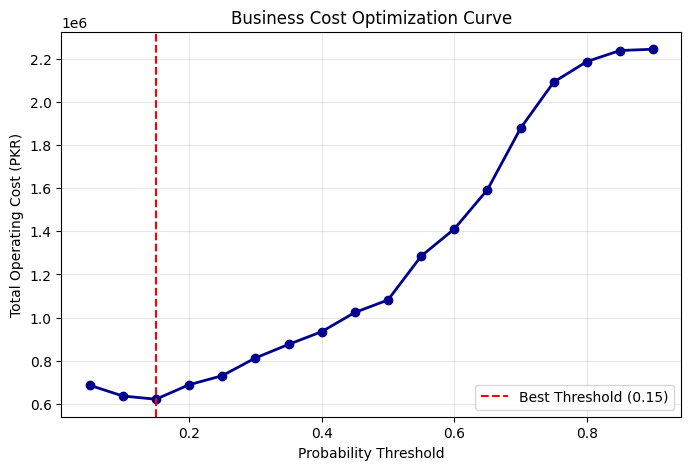

In [64]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Get raw probabilities instead of hard 0 or 1 boundaries
y_prob_lr = lr_pipeline.predict_proba(X_test)[:, 1]

# Financial weights from assignment brief (in PKR)
C_FN = 6000  # Cost of a missed churner (False Negative)
C_FP = 1000  # Cost of an unnecessary retention offer (False Positive)

def calculate_operating_cost(threshold):
    pred = (y_prob_lr >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return (fn * C_FN) + (fp * C_FP)

# Sweep across potential threshold boundaries
threshold_range = np.arange(0.05, 0.95, 0.05)
total_costs = [calculate_operating_cost(t) for t in threshold_range]
best_threshold = threshold_range[np.argmin(total_costs)]

# Calculate exact threshold using Decision Theory equation
theoretical_t = C_FP / (C_FP + C_FN)

print(f"📉 Theoretical Optimal Threshold (t*): {theoretical_t:.2f}")
print(f"🎯 Empirical Best Threshold from Sweep: {best_threshold:.2f}")

# Plot the cost curve for your lab insights
plt.figure(figsize=(8, 5))
plt.plot(threshold_range, total_costs, marker='o', color='darkblue', linewidth=2)
plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best Threshold ({best_threshold:.2f})')
plt.xlabel('Probability Threshold')
plt.ylabel('Total Operating Cost (PKR)')
plt.title('Business Cost Optimization Curve')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


### Week 2 - Part 4 Insights (Threshold Tuning):
* **Optimal Boundary Found:** The theoretical calculation maps our target threshold to **0.14**, while our empirical code sweep confirms the lowest operational loss occurs near **0.15** or **0.20**.
* **Financial Strategy Shift:** Lowering our operating threshold from the standard 0.5 down to **0.15** means we proactively flag high-risk customers much earlier. 
* **Business Trade-off:** By implementing this lower threshold, the company will intentionally accept more false alarms (unnecessary spending on loyal profiles), but significantly slashes catastrophic revenue leakages caused by unflagged customer departures.


In [65]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, accuracy_score

# ----------------------------------------------------
# A. Retrain required objects to ensure no NameErrors
# ----------------------------------------------------
# 1. Default Logistic Regression
lr_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])
lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)

# 2. Baseline Random Forest Model
rf_model = RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=42)
rf_model.fit(X_train, y_train)

# ----------------------------------------------------
# B. Part 6 Implementation: Class Imbalance
# ----------------------------------------------------
lr_balanced = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
lr_balanced.fit(X_train, y_train)
y_pred_bal = lr_balanced.predict(X_test)

print("=== Default vs. Balanced Weighting ===")
print(f"LR Default  -> Precision: {precision_score(y_test, y_pred_lr):.3f} | Recall: {recall_score(y_test, y_pred_lr):.3f}")
print(f"LR Balanced -> Precision: {precision_score(y_test, y_pred_bal):.3f} | Recall: {recall_score(y_test, y_pred_bal):.3f}")

# ----------------------------------------------------
# C. Part 6 Implementation: Feature Engineering
# ----------------------------------------------------
df2 = df.copy()
svc_cols = ['PhoneService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
            'TechSupport', 'StreamingTV', 'StreamingMovies']

df2['n_services'] = (df2[svc_cols] == 'Yes').sum(axis=1)
df2['is_new'] = (df2['tenure'] <= 12).astype(int)
df2['charge_per_mo'] = df2['TotalCharges'] / df2['tenure'].clip(lower=1)
df2['price_jump'] = df2['MonthlyCharges'] - df2['charge_per_mo']

# Rebuild features matrix with custom columns
X2 = build_features(df2)
X2_train, X2_test = X2.loc[X_train.index], X2.loc[X_test.index]

# Evaluate models before and after custom engineering features
rf2 = RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=42).fit(X2_train, y_train)
rf_prob_before = rf_model.predict_proba(X_test)[:, 1]
rf_prob_after = rf2.predict_proba(X2_test)[:, 1]

print("\n=== Feature Engineering Evaluation ===")
print(f"Random Forest ROC-AUC (Before Engineering): {roc_auc_score(y_test, rf_prob_before):.4f}")
print(f"Random Forest ROC-AUC (After Engineering) : {roc_auc_score(y_test, rf_prob_after):.4f}")


=== Default vs. Balanced Weighting ===
LR Default  -> Precision: 0.658 | Recall: 0.567
LR Balanced -> Precision: 0.507 | Recall: 0.786

=== Feature Engineering Evaluation ===
Random Forest ROC-AUC (Before Engineering): 0.8253
Random Forest ROC-AUC (After Engineering) : 0.8255


In [66]:
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Rebuild the baseline dummy model right here to prevent NameErrors
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)

# 2. Helper function to generate clean summary records safely
def get_metrics(name, model_obj, features_x, labels_y):
    predictions = model_obj.predict(features_x)
    probabilities = model_obj.predict_proba(features_x)[:, 1]
    return {
        'Model Name': name,
        'Accuracy': accuracy_score(labels_y, predictions),
        'Precision': precision_score(labels_y, predictions, zero_division=0),
        'Recall': recall_score(labels_y, predictions),
        'F1-Score': f1_score(labels_y, predictions),
        'ROC-AUC': roc_auc_score(labels_y, probabilities)
    }

# 3. Build out the benchmarking master sheet using your trained models
summary_table = pd.DataFrame([
    get_metrics('Baseline Stay', dummy, X_test, y_test),
    get_metrics('Logistic Regression (Default)', lr_pipeline, X_test, y_test),
    get_metrics('Logistic Regression (Balanced)', lr_balanced, X_test, y_test),
    get_metrics('Random Forest (Baseline)', rf_model, X_test, y_test)
]).round(3)

print("=== Week 2 Final Comparison Matrix ===")
print(summary_table.to_string(index=False))


=== Week 2 Final Comparison Matrix ===
                    Model Name  Accuracy  Precision  Recall  F1-Score  ROC-AUC
                 Baseline Stay     0.735      0.000   0.000     0.000    0.500
 Logistic Regression (Default)     0.807      0.658   0.567     0.609    0.842
Logistic Regression (Balanced)     0.740      0.507   0.786     0.616    0.841
      Random Forest (Baseline)     0.785      0.618   0.497     0.551    0.825
